# Chapter 5 — Linear Models and Regularization

**Sumber:** *scikit-learn Cookbook*, 3rd Ed. (John Sukup, Packt, 2025)

Model linear adalah titik awal hampir semua pekerjaan regresi: sederhana, cepat, dan mudah ditafsirkan. Namun ketika jumlah fitur besar, fitur saling berkorelasi (*multicollinearity*), atau data mengandung banyak *noise*, estimasi *Ordinary Least Squares* (OLS) menjadi tidak stabil dan mudah *overfitting*. Chapter ini membahas bagaimana **regularisasi** (Ridge, Lasso, ElasticNet) menstabilkan model linear, serta bagaimana model linear diperluas untuk menangkap pola non-linear lewat **polynomial features** dan **spline**.

**Daftar Isi**

1. 5.1 Pengantar Model Linear (Ordinary Least Squares)
2. 5.2 Ridge dan Lasso Regression
3. 5.3 ElasticNet dan Regularisasi
4. 5.4 Polynomial Regression
5. 5.5 Spline Interpolation
6. Latihan (Exercise 1–3: Ridge, Lasso, ElasticNet)
7. Ringkasan Chapter 5

> **Catatan:** Notebook ini mereproduksi kode dari Chapter 5 (urutan resep sama dengan notebook resmi Packt), dengan sedikit penyesuaian agar berjalan di scikit-learn 1.9 dan lebih jelas, lalu menjelaskan teori di balik setiap resep (bagian **Teori:**) dan menafsirkan hasil eksekusinya (bagian **Interpretasi:**).

## Import Library

In [1]:
%matplotlib inline
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures, SplineTransformer
from sklearn.pipeline import make_pipeline
from IPython.display import display

# Pengaturan tampilan gambar agar ukurannya moderat
plt.rcParams['figure.dpi'] = 90
sns.set_style('whitegrid')

print('numpy        :', np.__version__)
print('pandas       :', pd.__version__)
print('scikit-learn :', sklearn.__version__)

numpy        : 2.5.3
pandas       : 3.0.6
scikit-learn : 1.9.1


## 5.1 Pengantar Model Linear (Ordinary Least Squares)

**Teori:**

**Model regresi linear.** Untuk $n$ observasi dan $p$ fitur, model linear mengasumsikan target merupakan kombinasi linear dari fitur ditambah galat acak:

$$
y_i = \beta_0 + \sum_{j=1}^{p} \beta_j x_{ij} + \varepsilon_i, \qquad \mathbb{E}[\varepsilon_i]=0,\ \operatorname{Var}(\varepsilon_i)=\sigma^2 .
$$

Dalam notasi matriks (kolom pertama $X$ berisi angka 1 untuk intersep): $\mathbf{y} = X\boldsymbol\beta + \boldsymbol\varepsilon$.

**Ordinary Least Squares (OLS).** OLS memilih $\boldsymbol\beta$ yang meminimalkan *residual sum of squares*:

$$
\hat{\boldsymbol\beta}_{\text{OLS}} = \arg\min_{\boldsymbol\beta}\ \lVert \mathbf{y} - X\boldsymbol\beta \rVert_2^2 .
$$

Menurunkan terhadap $\boldsymbol\beta$ dan menyamakannya dengan nol menghasilkan **normal equation**:

$$
X^\top X\,\hat{\boldsymbol\beta} = X^\top \mathbf{y} \quad\Longrightarrow\quad \hat{\boldsymbol\beta}_{\text{OLS}} = (X^\top X)^{-1} X^\top \mathbf{y}.
$$

Secara geometris, $\hat{\mathbf y} = X\hat{\boldsymbol\beta}$ adalah proyeksi ortogonal $\mathbf y$ ke ruang kolom $X$, sehingga residual tegak lurus terhadap semua fitur. Menurut teorema **Gauss–Markov**, bila galat tidak berkorelasi dan homoskedastik, OLS adalah estimator linear *unbiased* dengan varians terkecil (BLUE). `LinearRegression` di scikit-learn tidak membalik matriks secara eksplisit, melainkan memakai solver *least squares* berbasis SVD/QR (`scipy.linalg.lstsq`) yang lebih stabil secara numerik.

**Masalah multikolinearitas.** Kovarians estimator OLS adalah $\operatorname{Var}(\hat{\boldsymbol\beta}) = \sigma^2 (X^\top X)^{-1}$. Bila beberapa kolom $X$ hampir merupakan kombinasi linear dari kolom lain, $X^\top X$ mendekati singular: nilai eigen terkecilnya mendekati nol sehingga $(X^\top X)^{-1}$ "meledak". Akibatnya koefisien punya varians sangat besar, bisa berubah tanda drastis hanya karena perubahan kecil pada data, dan sulit ditafsirkan — walaupun prediksi di dalam rentang data latih mungkin masih wajar. Dataset sintetis di resep ini sengaja dibuat demikian: 50 fitur terakhir adalah salinan 50 fitur pertama ditambah *noise* kecil ($\sigma=0.1$), dan hanya 10 dari 100 fitur yang benar-benar informatif.

**Metrik evaluasi.**

$$
\text{MSE} = \frac{1}{n}\sum_{i=1}^{n} (y_i - \hat y_i)^2, \qquad
R^2 = 1 - \frac{\sum_i (y_i-\hat y_i)^2}{\sum_i (y_i-\bar y)^2}.
$$

MSE dinyatakan dalam satuan kuadrat target (sehingga skalanya bergantung pada skala $y$; di sini target dikalikan 1000 sehingga MSE berukuran sangat besar), sedangkan $R^2$ adalah proporsi variansi target yang dijelaskan model. $R^2=1$ berarti prediksi sempurna, $R^2=0$ setara dengan selalu memprediksi rata-rata, dan $R^2$ pada data uji bisa negatif bila model lebih buruk dari rata-rata.

**Train/test split.** Model dinilai pada data yang tidak dipakai saat *fitting* agar kita mengukur kemampuan **generalisasi**, bukan sekadar kemampuan menghafal data latih.

Korelasi feature_0 vs feature_50: 0.9951
Bilangan kondisi (condition number) X: 31.5


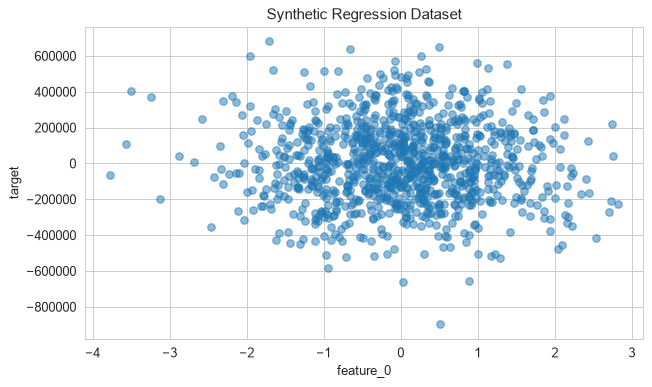

In [2]:
# Membuat dataset regresi sintetis: 100 fitur, hanya 10 yang informatif
X, y = make_regression(n_samples=1000,
                       n_features=100,
                       n_informative=10,
                       noise=20,
                       random_state=123)

# Menambahkan multikolinearitas: fitur 50..99 = salinan fitur 0..49 + noise kecil
rng = np.random.default_rng(123)   # seed agar hasil reprodusibel
for i in range(50, 100):
    X[:, i] = X[:, i - 50] + rng.normal(0, 0.1, size=1000)

# Nama fitur
feature_names = [f'feature_{i}' for i in range(100)]

# Ambil hanya fitur pertama untuk keperluan visualisasi
X_plot = X[:, 0].reshape(-1, 1)

# Menambahkan sedikit non-linearitas dan memperbesar skala target
y = y * 1000
y = y + np.sin(X_plot.ravel()) * 150 + np.exp(X_plot.ravel() / 10)

# Simpan ke DataFrame
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y
df_plot = pd.DataFrame({'feature_0': X_plot.ravel(), 'target': y})

# Cek korelasi pasangan fitur yang sengaja dibuat kolinear
print('Korelasi feature_0 vs feature_50:', round(np.corrcoef(X[:, 0], X[:, 50])[0, 1], 4))
print('Bilangan kondisi (condition number) X:', f'{np.linalg.cond(X):.1f}')

# Visualisasi singkat
plt.figure(figsize=(8, 4.5))
plt.scatter(X_plot, y, alpha=0.5)
plt.xlabel('feature_0')
plt.ylabel('target')
plt.title('Synthetic Regression Dataset')
plt.show()

**Interpretasi:**

- Korelasi `feature_0` dengan `feature_50` sebesar **0.995**: kedua kolom praktis identik, begitu juga 49 pasangan lainnya. Bilangan kondisi $X$ (~31.5) masih moderat karena *noise* penyalin $\sigma=0.1$ belum membuat matriks benar-benar singular, tetapi sudah cukup untuk membuat koefisien OLS tidak stabil (terlihat di sel berikutnya).
- Pada scatter plot, `feature_0` vs target hanya berupa awan titik dengan tren lemah. Ini wajar: target dibentuk oleh 10 fitur informatif sekaligus, jadi satu fitur saja hanya menjelaskan sebagian kecil variasi. Komponen $\sin$ dan $\exp$ yang ditambahkan sangat kecil dibanding skala target (~$10^5$), sehingga tidak tampak di plot.

Mean Squared Error: 46808360868.71
R-squared: 0.06
R-squared (train): 0.34


,coef_feature_j,coef_feature_j+50,jumlah
j=0,11976.4,-18668.1,-6691.8
j=1,-36922.3,34911.2,-2011.1
j=2,24271.3,-39227.3,-14955.9
j=3,-82358.0,108181.7,25823.7
j=4,4056.5,-5000.8,-944.3


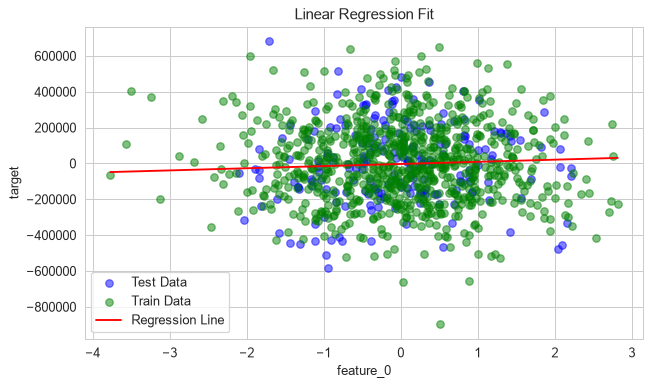

In [3]:
# Membagi data latih dan data uji (80:20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=123)

# Membuat dan melatih model Linear Regression (OLS)
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Prediksi pada data uji
y_pred = linear_model.predict(X_test)

# Evaluasi dengan MSE dan R-squared
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f'Mean Squared Error: {mse:.2f}')
print(f'R-squared: {r2:.2f}')
print(f'R-squared (train): {linear_model.score(X_train, y_train):.2f}')

# Lihat ketidakstabilan koefisien pada pasangan fitur kolinear
pairs = pd.DataFrame({
    'coef_feature_j': linear_model.coef_[:5],
    'coef_feature_j+50': linear_model.coef_[50:55],
}, index=[f'j={j}' for j in range(5)])
pairs['jumlah'] = pairs.sum(axis=1)
display(pairs.round(1))

# Visualisasi data dan garis regresi (menggunakan feature_0)
plt.figure(figsize=(8, 4.5))
plt.scatter(X_test[:, 0], y_test, color='blue', alpha=0.5, label='Test Data')
plt.scatter(X_train[:, 0], y_train, color='green', alpha=0.5, label='Train Data')

# Garis prediksi: feature_0 divariasikan, fitur lain ditahan = 0
X_line = np.linspace(df['feature_0'].min(), df['feature_0'].max(), 100).reshape(-1, 1)
X_line_full = np.zeros((100, len(feature_names)))
X_line_full[:, 0] = X_line.ravel()
y_line = linear_model.predict(X_line_full)

plt.plot(X_line, y_line, color='red', label='Regression Line')
plt.xlabel('feature_0')
plt.ylabel('target')
plt.title('Linear Regression Fit')
plt.legend()
plt.show()

**Interpretasi:**

- OLS menghasilkan $R^2$ uji hanya **0.06** (MSE ≈ $4.68\times10^{10}$, atau RMSE ≈ 216 ribu satuan target), sedangkan $R^2$ latih **0.34**. Selisih yang besar ini menunjukkan **overfitting**: 100 koefisien yang dipasang pada 800 sampel ikut "menghafal" *noise*.
- Mengapa $R^2$ secara umum rendah? `make_regression` mengacak posisi 10 fitur informatif (`shuffle=True`), dan target dibuat **sebelum** kolom 50–99 ditimpa. Jadi bila sebagian fitur informatif berada di kolom 50–99, sinyal aslinya hilang dari $X$ dan berubah menjadi *noise* yang tidak bisa dijelaskan oleh model apa pun. Inilah yang membuat dataset ini sengaja sulit.
- Tabel pasangan koefisien memperlihatkan gejala klasik multikolinearitas: koefisien `feature_j` dan `feature_j+50` bernilai besar dengan **tanda berlawanan** (mis. −82 ribu vs +108 ribu), sedangkan jumlahnya jauh lebih kecil. Model hanya "peduli" pada jumlahnya; pembagian bobot di antara dua kolom kembar ditentukan oleh *noise*, sehingga koefisien individual tidak dapat ditafsirkan.
- Garis regresi pada plot adalah irisan model ketika fitur lain bernilai 0, sehingga hanya menggambarkan efek `feature_0` (tanpa kembarannya `feature_50`).

## 5.2 Ridge dan Lasso Regression

**Teori:**

**Bias–variance trade-off.** Untuk titik baru $x_0$ dengan $y_0 = f(x_0)+\varepsilon$, galat prediksi kuadrat yang diharapkan dapat diuraikan menjadi

$$
\mathbb{E}\big[(y_0 - \hat f(x_0))^2\big] = \underbrace{\big(\mathbb{E}[\hat f(x_0)] - f(x_0)\big)^2}_{\text{Bias}^2} + \underbrace{\operatorname{Var}\big(\hat f(x_0)\big)}_{\text{Variance}} + \underbrace{\sigma^2}_{\text{irreducible}} .
$$

OLS tidak bias, tetapi dengan banyak fitur kolinear variansnya sangat besar. Regularisasi **sengaja menambahkan sedikit bias** (menyusutkan koefisien ke arah nol) untuk **mengurangi varians secara drastis**, sehingga total galat prediksi bisa lebih kecil.

**Ridge Regression (penalti L2).** Ridge menambahkan penalti kuadrat norma koefisien:

$$
\hat{\boldsymbol\beta}_{\text{ridge}} = \arg\min_{\boldsymbol\beta}\ \lVert \mathbf y - X\boldsymbol\beta\rVert_2^2 + \alpha \lVert \boldsymbol\beta\rVert_2^2, \qquad \lVert\boldsymbol\beta\rVert_2^2=\sum_{j=1}^p \beta_j^2 .
$$

(intersep $\beta_0$ tidak dipenalti). Objektif ini masih kuadratik sehingga punya **solusi tertutup (closed form)**:

$$
\hat{\boldsymbol\beta}_{\text{ridge}} = (X^\top X + \alpha I)^{-1} X^\top \mathbf y .
$$

Penambahan $\alpha I$ menggeser setiap nilai eigen $d_j^2$ dari $X^\top X$ menjadi $d_j^2+\alpha>0$, sehingga matriks selalu dapat dibalik walaupun fitur kolinear atau $p>n$. Lewat SVD $X=UDV^\top$, prediksi ridge adalah $\hat{\mathbf y} = \sum_j u_j \frac{d_j^2}{d_j^2+\alpha} u_j^\top \mathbf y$: arah dengan nilai singular kecil (arah kolinear yang tidak stabil) disusutkan paling kuat. Ridge **menyusutkan** koefisien tetapi hampir tidak pernah membuatnya tepat nol; untuk dua fitur yang hampir identik, ridge cenderung membagi bobot secara merata di antara keduanya.

**Lasso Regression (penalti L1).** scikit-learn meminimalkan

$$
\hat{\boldsymbol\beta}_{\text{lasso}} = \arg\min_{\boldsymbol\beta}\ \frac{1}{2n}\lVert \mathbf y - X\boldsymbol\beta\rVert_2^2 + \alpha \lVert \boldsymbol\beta\rVert_1, \qquad \lVert\boldsymbol\beta\rVert_1 = \sum_{j=1}^p |\beta_j| .
$$

Perhatikan faktor $\tfrac{1}{2n}$: skala `alpha` pada `Lasso` **tidak sebanding** dengan `alpha` pada `Ridge` (yang tidak memakai $\tfrac{1}{2n}$). Penalti L1 tidak dapat diturunkan di $\beta_j=0$, sehingga tidak ada solusi tertutup; scikit-learn memakai **coordinate descent**. Untuk fitur terstandardisasi, pembaruan tiap koordinat berbentuk **soft-thresholding**:

$$
\beta_j \leftarrow S(z_j, \alpha) = \operatorname{sign}(z_j)\,\max(|z_j| - \alpha,\ 0),
$$

dengan $z_j$ korelasi fitur $j$ dengan residual parsial. Bila $|z_j|\le\alpha$, koefisien menjadi **tepat nol** — inilah sebabnya Lasso menghasilkan model **sparse** dan sekaligus melakukan **seleksi fitur**.

**Mengapa L1 menghasilkan sparsity (sudut pandang geometris).** Masalah berpenalti setara dengan masalah berkendala $\min \lVert\mathbf y - X\boldsymbol\beta\rVert^2$ s.t. $\lVert\boldsymbol\beta\rVert_q \le t$. Kontur RSS berbentuk elips. Daerah kendala L2 berbentuk bola (tanpa sudut), sehingga elips biasanya menyentuhnya di titik yang semua koordinatnya tak nol. Daerah kendala L1 berbentuk belah ketupat/*cross-polytope* yang memiliki **sudut tajam di sumbu-sumbu**, sehingga titik singgung pertama sangat sering terjadi di sudut — di mana sebagian koordinat bernilai nol. Dari sudut pandang Bayesian, Ridge setara dengan *prior* Gaussian pada koefisien, sedangkan Lasso setara dengan *prior* Laplace yang runcing di nol.

**Peran $\alpha$.** $\alpha=0$ mengembalikan OLS; $\alpha\to\infty$ memaksa semua koefisien ke nol (model hanya memprediksi rata-rata). Karena penalti bergantung pada besar koefisien, **skala fitur penting**: fitur harus berada pada skala yang sebanding (biasanya dengan `StandardScaler`) agar penalti adil. Pada dataset ini fitur dari `make_regression` sudah berskala ~N(0,1).

**Memilih $\alpha$ dengan cross-validation.** $\alpha$ adalah *hyperparameter*, sehingga dipilih dengan meminimalkan galat validasi silang $K$-fold:

$$
\hat\alpha = \arg\min_{\alpha}\ \frac{1}{K}\sum_{k=1}^{K} \text{MSE}_k(\alpha),
$$

dengan $\text{MSE}_k$ dihitung pada *fold* ke-$k$ setelah model dilatih pada $K-1$ fold lainnya. scikit-learn menyediakan `RidgeCV` (secara default memakai *efficient leave-one-out* berbasis SVD) dan `LassoCV`/`ElasticNetCV` yang menghitung seluruh *regularization path* secara efisien dengan *warm start*.

,Model,Mean Squared Error,R-squared
0,Ridge Regression,45346869860.63,0.09
1,Lasso Regression,46647602406.85,0.06
2,Linear Regression,46808360868.71,0.06


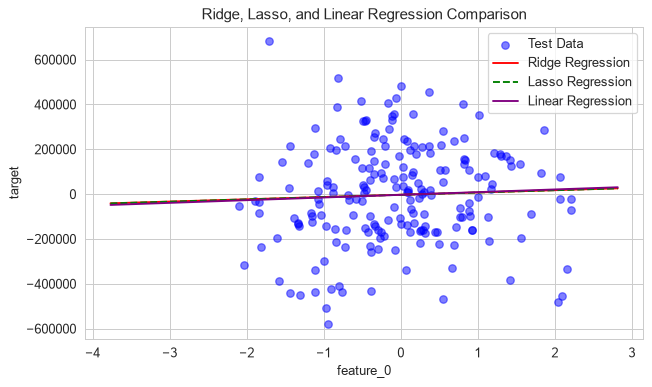

In [4]:
# Ridge: alpha mengontrol kekuatan regularisasi L2
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train, y_train)

# Lasso: alpha lebih besar, max_iter dinaikkan agar coordinate descent konvergen
lasso_model = Lasso(alpha=10.0, max_iter=10000, tol=0.001)
lasso_model.fit(X_train, y_train)

# Prediksi
y_pred_ridge = ridge_model.predict(X_test)
y_pred_lasso = lasso_model.predict(X_test)
y_pred_linear = linear_model.predict(X_test)

# Hitung metrik untuk ketiga model
metrics = {
    'Model': ['Ridge Regression', 'Lasso Regression', 'Linear Regression'],
    'Mean Squared Error': [
        mean_squared_error(y_test, y_pred_ridge),
        mean_squared_error(y_test, y_pred_lasso),
        mean_squared_error(y_test, y_pred_linear),
    ],
    'R-squared': [
        r2_score(y_test, y_pred_ridge),
        r2_score(y_test, y_pred_lasso),
        r2_score(y_test, y_pred_linear),
    ],
}

# DataFrame diurutkan berdasarkan MSE
metrics_df = pd.DataFrame(metrics).sort_values('Mean Squared Error', ascending=True)

# Format angka agar mudah dibaca
metrics_df['Mean Squared Error'] = metrics_df['Mean Squared Error'].map('{:.2f}'.format)
metrics_df['R-squared'] = metrics_df['R-squared'].map('{:.2f}'.format)
display(metrics_df)

# Visualisasi (menggunakan feature_0, fitur lain = 0)
plt.figure(figsize=(8, 4.5))
plt.scatter(X_test[:, 0], y_test, color='blue', alpha=0.5, label='Test Data')

X_line = np.linspace(df['feature_0'].min(), df['feature_0'].max(), 100).reshape(-1, 1)
X_line_full = np.zeros((100, len(feature_names)))
X_line_full[:, 0] = X_line.ravel()

y_line_ridge = ridge_model.predict(X_line_full)
y_line_lasso = lasso_model.predict(X_line_full)
y_line_linear = linear_model.predict(X_line_full)

plt.plot(X_line, y_line_ridge, color='red', label='Ridge Regression')
plt.plot(X_line, y_line_lasso, color='green', linestyle='--', label='Lasso Regression')
plt.plot(X_line, y_line_linear, color='purple', label='Linear Regression')
plt.xlabel('feature_0')
plt.ylabel('target')
plt.title('Ridge, Lasso, and Linear Regression Comparison')
plt.legend()
plt.show()

**Interpretasi:**

- **Ridge** ($\alpha=1$) memberikan hasil terbaik di antara ketiganya: $R^2$ uji naik dari 0.06 menjadi **0.09** dan MSE turun sekitar 3%. Penalti L2 meredam koefisien kembar yang saling meniadakan, sehingga variansnya berkurang.
- **Lasso** ($\alpha=10$) hampir identik dengan OLS ($R^2$ 0.06). Penyebabnya adalah skala: koefisien di sini berorde $10^4$–$10^5$ (target dikali 1000), sedangkan ambang soft-thresholding hanya sebesar $\alpha=10$ (dan objektif Lasso pun dibagi $2n$). Penalti tersebut terlalu kecil untuk menolkan koefisien apa pun (dibuktikan di sel berikut). Pelajaran praktis: nilai $\alpha$ tidak bermakna secara absolut — harus disesuaikan dengan skala data dan dipilih lewat validasi silang.
- Pada plot, ketiga garis hampir berimpit dan hanya berbeda kemiringan: Ridge sedikit lebih landai karena koefisien `feature_0` disusutkan.

*Tambahan (bukan bagian dari notebook asli):* sel berikut memverifikasi teori di atas secara numerik — (1) solusi tertutup Ridge $(X_c^\top X_c+\alpha I)^{-1}X_c^\top \mathbf y_c$ pada data yang sudah dipusatkan (agar intersep tidak dipenalti) sama dengan hasil `Ridge`; (2) jumlah koefisien yang tepat nol (sparsity) pada tiap model; (3) pemilihan $\alpha$ dengan `RidgeCV` dan `LassoCV`.

Selisih maksimum koefisien closed-form vs Ridge(): 7.57e-09
Linear : koefisien = 0 ->   0 dari 100, ||beta||_2 = 799,225
Ridge  : koefisien = 0 ->   0 dari 100, ||beta||_2 = 619,253
Lasso  : koefisien = 0 ->   0 dari 100, ||beta||_2 = 780,119



RidgeCV  -> alpha terbaik = 323.746, R2 uji = 0.1439
LassoCV  -> alpha terbaik = 9426.685, R2 uji = 0.2054, fitur aktif = 12


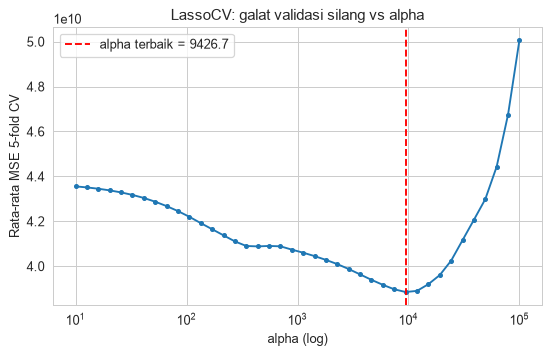

In [5]:
from sklearn.linear_model import RidgeCV, LassoCV

# (1) Solusi tertutup Ridge pada data terpusat
X_c = X_train - X_train.mean(axis=0)
y_c = y_train - y_train.mean()
alpha = 1.0
beta_closed = np.linalg.solve(X_c.T @ X_c + alpha * np.eye(X_c.shape[1]), X_c.T @ y_c)
print('Selisih maksimum koefisien closed-form vs Ridge():',
      f'{np.max(np.abs(beta_closed - ridge_model.coef_)):.2e}')

# (2) Sparsity: berapa koefisien yang tepat nol?
for name, m in [('Linear', linear_model), ('Ridge', ridge_model), ('Lasso', lasso_model)]:
    print(f'{name:7s}: koefisien = 0 -> {np.sum(m.coef_ == 0):3d} dari {m.coef_.size}, '
          f'||beta||_2 = {np.linalg.norm(m.coef_):,.0f}')

# (3) Memilih alpha dengan cross-validation
ridge_cv = RidgeCV(alphas=np.logspace(-3, 3, 50)).fit(X_train, y_train)
lasso_cv = LassoCV(alphas=np.logspace(1, 5, 40), cv=5, max_iter=10000,
                   random_state=123).fit(X_train, y_train)
print(f'\nRidgeCV  -> alpha terbaik = {ridge_cv.alpha_:.3f}, R2 uji = {ridge_cv.score(X_test, y_test):.4f}')
print(f'LassoCV  -> alpha terbaik = {lasso_cv.alpha_:.3f}, R2 uji = {lasso_cv.score(X_test, y_test):.4f}, '
      f'fitur aktif = {np.sum(lasso_cv.coef_ != 0)}')

# Kurva galat CV Lasso terhadap alpha
plt.figure(figsize=(7, 4))
plt.semilogx(lasso_cv.alphas_, lasso_cv.mse_path_.mean(axis=1), marker='o', ms=3)
plt.axvline(lasso_cv.alpha_, color='red', ls='--', label=f'alpha terbaik = {lasso_cv.alpha_:.1f}')
plt.xlabel('alpha (log)')
plt.ylabel('Rata-rata MSE 5-fold CV')
plt.title('LassoCV: galat validasi silang vs alpha')
plt.legend()
plt.show()

**Interpretasi:**

- Selisih koefisien solusi tertutup dan `Ridge()` hanya ~$10^{-8}$ (galat pembulatan), membuktikan bahwa `Ridge` memang menyelesaikan $(X_c^\top X_c+\alpha I)^{-1}X_c^\top\mathbf y_c$ dengan intersep yang tidak dipenalti.
- Tidak ada satu pun koefisien yang nol pada OLS, Ridge, maupun Lasso($\alpha=10$). Ridge memperkecil norma $\lVert\boldsymbol\beta\rVert_2$ dari ~799 ribu menjadi ~619 ribu (penyusutan), sedangkan Lasso($\alpha=10$) nyaris tidak berubah — sesuai penjelasan di atas.
- Dengan validasi silang, $\alpha$ optimal ternyata jauh lebih besar: **RidgeCV** memilih $\alpha\approx324$ ($R^2$ uji 0.144) dan **LassoCV** memilih $\alpha\approx9{,}427$ ($R^2$ uji **0.205**) dengan hanya **12 fitur aktif** dari 100 — sangat dekat dengan 10 fitur informatif sesungguhnya. Di sinilah keunggulan L1 terlihat: dengan $\alpha$ yang tepat, Lasso membuang fitur pengganggu dan cenderung memilih satu wakil dari setiap pasangan kembar.
- Kurva MSE-CV berbentuk "U" khas bias–variance: $\alpha$ kecil → varians tinggi, $\alpha$ terlalu besar → bias tinggi (semua koefisien ditekan ke nol).

## 5.3 ElasticNet dan Regularisasi

**Teori:**

**Objektif ElasticNet.** ElasticNet menggabungkan penalti L1 dan L2. Dalam parametrisasi scikit-learn:

$$
\hat{\boldsymbol\beta}_{\text{EN}} = \arg\min_{\boldsymbol\beta}\ \frac{1}{2n}\lVert \mathbf y - X\boldsymbol\beta\rVert_2^2 + \alpha\,\rho\,\lVert\boldsymbol\beta\rVert_1 + \frac{\alpha(1-\rho)}{2}\lVert\boldsymbol\beta\rVert_2^2 ,
$$

dengan $\rho$ = `l1_ratio` $\in[0,1]$. $\rho=1$ memberikan Lasso murni, sedangkan $\rho=0$ memberikan penalti ridge murni (dengan skala yang berbeda dari kelas `Ridge`). Pembaruan *coordinate descent*-nya adalah soft-thresholding yang kemudian dibagi faktor $1+\alpha(1-\rho)$:

$$
\beta_j \leftarrow \frac{S(z_j,\ \alpha\rho)}{1 + \alpha(1-\rho)} .
$$

**Mengapa perlu ElasticNet?**

1. **Efek pengelompokan (*grouping effect*).** Jika beberapa fitur sangat berkorelasi, Lasso cenderung memilih satu secara agak acak dan membuang sisanya — hasilnya tidak stabil. Komponen L2 membuat objektif *strictly convex*, sehingga fitur yang berkorelasi tinggi cenderung mendapat koefisien yang mirip dan masuk/keluar model bersama-sama. Ini sangat relevan untuk dataset kita yang berisi 50 pasangan fitur hampir identik.
2. **Kasus $p>n$.** Lasso paling banyak memilih $n$ fitur; ElasticNet tidak memiliki batasan ini.
3. Tetap mempertahankan **sparsity** dari komponen L1.

**Regularization / coefficient path.** Dengan memvariasikan $\alpha$ dari kecil ke besar, kita dapat memplot setiap $\hat\beta_j(\alpha)$. Pada $\alpha$ kecil koefisien mendekati OLS; seiring $\alpha$ membesar, koefisien menyusut dan (karena komponen L1) satu per satu menjadi nol, hingga semuanya nol ketika $\alpha \ge \alpha_{\max} = \max_j |x_j^\top \mathbf y| / (n\rho)$. Plot ini memperlihatkan fitur mana yang paling "tahan" terhadap penalti, yaitu yang paling penting. Dalam praktik, kombinasi $(\alpha,\rho)$ dipilih dengan `ElasticNetCV`.

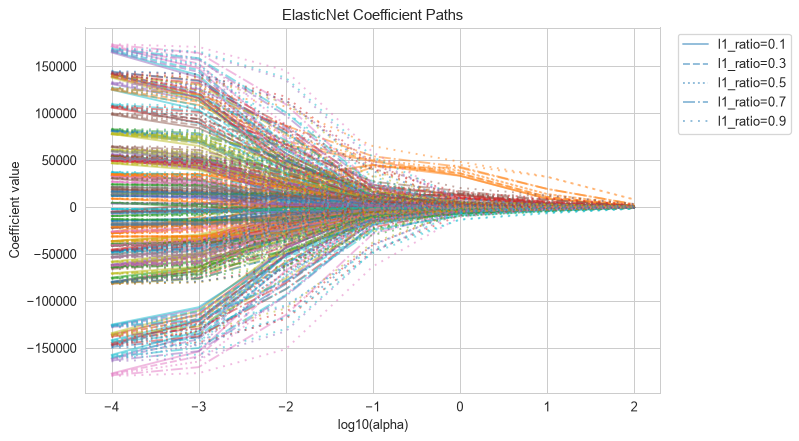

Jumlah koefisien non-nol:


,alpha=0.0001,alpha=0.001,alpha=0.01,alpha=0.1,alpha=1,alpha=10,alpha=100
l1_ratio=0.1,100,100,100,100,100,100,98
l1_ratio=0.3,100,100,100,100,100,100,98
l1_ratio=0.5,100,100,100,100,100,100,99
l1_ratio=0.7,100,100,100,100,99,100,99
l1_ratio=0.9,100,100,100,100,100,100,100


,Model,Mean Squared Error,R-squared
3,ElasticNet Regression,42541958455.85,0.15
0,Ridge Regression,45346869860.63,0.09
1,Lasso Regression,46647602406.85,0.06
2,Linear Regression,46808360868.71,0.06


In [6]:
# Rentang alpha dan l1_ratio yang akan diuji
alphas = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]
l1_ratios = [0.1, 0.3, 0.5, 0.7, 0.9]
linestyles = ['solid', 'dashed', 'dotted', 'dashdot', (0, (1, 3))]

# Simpan koefisien untuk plotting
coef_paths = []

plt.figure(figsize=(9, 5))
with warnings.catch_warnings():
    # alpha sangat kecil pada data kolinear bisa memicu ConvergenceWarning; disembunyikan agar rapi
    warnings.simplefilter('ignore')
    for l1_ratio, ls in zip(l1_ratios, linestyles):
        coefs = []
        for alpha in alphas:
            elastic_model = ElasticNet(alpha=alpha, l1_ratio=l1_ratio, random_state=123,
                                       max_iter=10000, tol=1e-4)
            elastic_model.fit(X_train, y_train)
            coefs.append(elastic_model.coef_)
        coefs = np.array(coefs)
        coef_paths.append(coefs)

        # Plot jalur koefisien untuk seluruh 100 fitur
        for feature_idx in range(X_train.shape[1]):
            plt.plot(np.log10(alphas), coefs[:, feature_idx],
                     label=f'l1_ratio={l1_ratio}' if feature_idx == 0 else None,
                     alpha=0.5, linestyle=ls)

plt.xlabel('log10(alpha)')
plt.ylabel('Coefficient value')
plt.title('ElasticNet Coefficient Paths')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

# Ringkasan: jumlah koefisien non-nol per kombinasi (alpha, l1_ratio)
nonzero = pd.DataFrame([[int(np.sum(c != 0)) for c in path] for path in coef_paths],
                       index=[f'l1_ratio={r}' for r in l1_ratios],
                       columns=[f'alpha={a}' for a in alphas])
print('Jumlah koefisien non-nol:')
display(nonzero)

# Model ElasticNet dengan l1_ratio seimbang dan alpha moderat
elastic_model = ElasticNet(alpha=1.0, l1_ratio=0.5, random_state=123, max_iter=10000, tol=1e-4)
elastic_model.fit(X_train, y_train)

elastic_pred = elastic_model.predict(X_test)
elastic_mse = mean_squared_error(y_test, elastic_pred)
elastic_r2 = r2_score(y_test, elastic_pred)

# Tambahkan hasil ElasticNet ke tabel metrik
new_row = pd.DataFrame({
    'Model': ['ElasticNet Regression'],
    'Mean Squared Error': [elastic_mse],
    'R-squared': [elastic_r2],
})

# Buang entri ElasticNet lama (jika sel dijalankan ulang), ubah kembali string -> float
metrics_df = metrics_df[~metrics_df['Model'].str.contains('ElasticNet')].copy()
metrics_df['Mean Squared Error'] = metrics_df['Mean Squared Error'].astype(float)
metrics_df['R-squared'] = metrics_df['R-squared'].astype(float)

metrics_df = pd.concat([metrics_df, new_row], ignore_index=True)
metrics_df = metrics_df.sort_values('Mean Squared Error', ascending=True)

metrics_df['Mean Squared Error'] = metrics_df['Mean Squared Error'].map('{:.2f}'.format)
metrics_df['R-squared'] = metrics_df['R-squared'].map('{:.2f}'.format)
display(metrics_df)

**Interpretasi:**

- **Coefficient path plot:** untuk $\alpha \le 0.1$ koefisien tetap besar dan tersebar luas (mendekati OLS, termasuk pasangan bertanda berlawanan). Mulai $\alpha=1$ semua jalur menyusut tajam ke arah nol, dan pada $\alpha=100$ hampir semuanya sudah dekat nol. Garis dengan `l1_ratio` kecil (lebih banyak L2) menyusut lebih cepat pada $\alpha$ yang sama karena penalti L2 sangat kuat terhadap koefisien bernilai besar.
- **Tabel jumlah koefisien non-nol:** hampir semua sel bernilai 100; hanya beberapa koefisien yang menjadi nol pada $\alpha=100$. Sekali lagi, ini karena skala koefisien sangat besar dibanding ambang L1 $\alpha\rho$ — sparsity yang berarti baru muncul pada $\alpha$ ribuan, seperti yang ditemukan LassoCV.
- **ElasticNet($\alpha=1$, `l1_ratio=0.5`)** menjadi model terbaik pada tabel: $R^2$ uji **0.15**, MSE ≈ $4.25\times10^{10}$. Dalam parametrisasi scikit-learn, komponen L2-nya setara dengan Ridge berpenalti sekitar $n\,\alpha(1-\rho) = 800 \times 1 \times 0.5 = 400$ — dekat dengan $\alpha$ optimal RidgeCV (~324). Jadi keunggulannya di sini terutama berasal dari penyusutan L2 yang kuat, yang paling cocok untuk data penuh fitur kembar.

## 5.4 Polynomial Regression

**Teori:**

**Basis expansion.** Model linear "linear" terhadap **parameter**, bukan harus terhadap fitur mentah. Kita bisa mengganti $x$ dengan vektor fungsi basis $\phi(x)$ lalu tetap memakai OLS:

$$
y = \beta_0 + \beta_1 x + \beta_2 x^2 + \dots + \beta_d x^d + \varepsilon = \boldsymbol\beta^\top \phi(x) + \varepsilon,\qquad \phi(x) = (1, x, x^2, \dots, x^d).
$$

`PolynomialFeatures(degree=d)` membentuk matriks desain $\Phi$ (matriks Vandermonde untuk satu fitur); untuk $p$ fitur ia juga membentuk semua suku interaksi, sehingga jumlah kolom menjadi $\binom{p+d}{d}$ — tumbuh sangat cepat. Solusinya tetap normal equation: $\hat{\boldsymbol\beta} = (\Phi^\top\Phi)^{-1}\Phi^\top\mathbf y$.

**Kompleksitas model dan bias–variance.** Derajat $d$ mengatur kapasitas model: $d$ kecil → *underfitting* (bias tinggi), $d$ besar → *overfitting* (varians tinggi, osilasi liar di tepi data — fenomena Runge). Derajat optimal dipilih berdasarkan galat pada data **uji/validasi**, bukan data latih (galat latih selalu turun saat $d$ naik karena model bersarang).

**Catatan numerik.** Kolom $x, x^2, x^3, \dots$ sangat berkorelasi dan skalanya berbeda jauh (di sini $x\in[-50,50]$ sehingga $x^5$ mencapai $\sim 3\times10^8$), membuat $\Phi^\top\Phi$ *ill-conditioned*. Dalam praktik dianjurkan menskalakan $x$ terlebih dahulu dan/atau menambahkan regularisasi Ridge pada fitur polinomial.

**Analisis residual.** Plot residual $e_i = y_i - \hat y_i$ terhadap $\hat y_i$ semestinya tampak seperti awan acak di sekitar nol tanpa pola. Pola sistematis (gelombang, corong) menandakan model belum menangkap struktur data (bias) atau varians galat tidak konstan (heteroskedastisitas).

Target di resep ini adalah $y = 2x + 27\sin(x/8) + \varepsilon$, $\varepsilon\sim N(0,4^2)$, sehingga tidak ada polinomial berderajat rendah yang dapat menirunya dengan sempurna di seluruh rentang $[-50,50]$ (sinus memiliki beberapa periode di rentang ini).

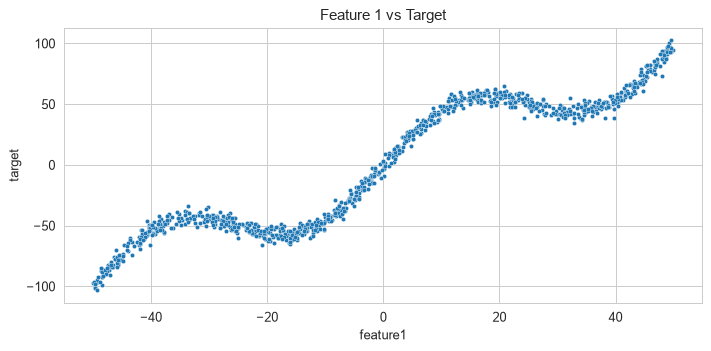

In [7]:
# Dataset sintetis dengan hubungan non-linear
np.random.seed(123)
n_samples = 1000
X = np.random.uniform(-50, 50, (n_samples, 1))

# Target: komponen linear + komponen sinus + noise
y = (2 * X[:, 0]
     + 27 * np.sin(X[:, 0] / 8)
     + np.random.normal(0, 4, n_samples))

data = pd.DataFrame(X, columns=['feature1'])
data['target'] = y

plt.figure(figsize=(8, 4))
sns.scatterplot(data=data, x='feature1', y='target', s=12)
plt.title('Feature 1 vs Target')
plt.tight_layout()
plt.show()

**Interpretasi:**

Scatter plot memperlihatkan tren naik yang kuat (komponen $2x$) yang "bergelombang" mengikuti $27\sin(x/8)$ dengan periode $16\pi \approx 50$, sehingga di rentang $[-50,50]$ terdapat sekitar dua gelombang penuh. Sebaran vertikal di sekitar kurva berasal dari *noise* $N(0, 4^2)$. Pola ini linear secara global tetapi non-linear secara lokal — sulit ditiru oleh polinomial berderajat rendah.


Model Performance Metrics:
 Degree        MSE       R2
      1 317.005037 0.891135
      2 316.818454 0.891199
      3 268.477397 0.907800
      4 268.230101 0.907885
      5 811.070884 0.721464


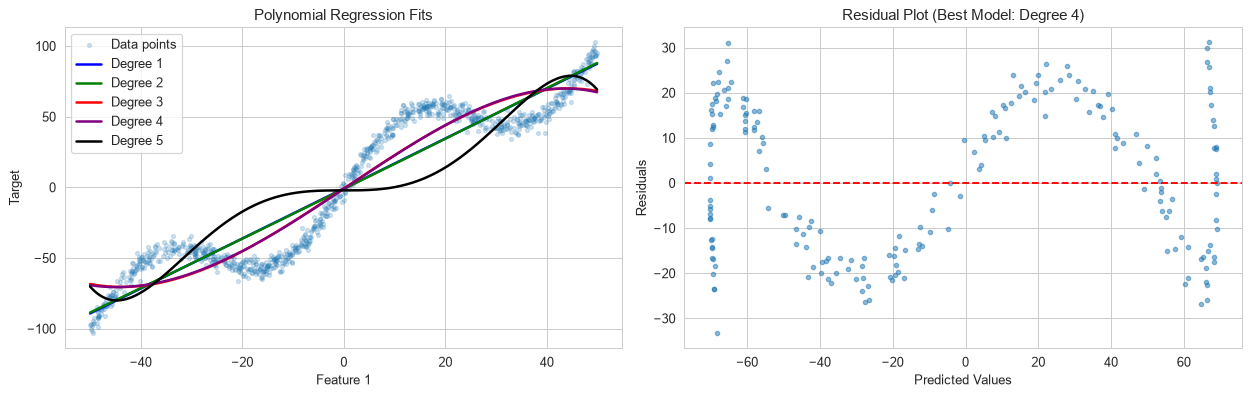

In [8]:
# Gunakan dataset sintetis di atas
X = data[['feature1']]
y = data['target']

degrees = [1, 2, 3, 4, 5]
results = []

for degree in degrees:
    # Transformasi ke fitur polinomial (termasuk kolom bias = 1)
    poly = PolynomialFeatures(degree=degree)
    X_poly = poly.fit_transform(X)

    # Split latih/uji (random_state sama -> baris yang sama untuk setiap derajat)
    X_train, X_test, y_train, y_test = train_test_split(X_poly, y, test_size=0.2, random_state=123)

    poly_model = LinearRegression()
    poly_model.fit(X_train, y_train)
    y_pred = poly_model.predict(X_test)

    results.append({
        'Degree': degree,
        'MSE': mean_squared_error(y_test, y_pred),
        'R2': r2_score(y_test, y_pred),
    })

results_df = pd.DataFrame(results)
print('\nModel Performance Metrics:')
print(results_df.to_string(index=False))

# Visualisasi kurva polinomial untuk tiap derajat
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
ax1.scatter(X['feature1'], y, alpha=0.2, s=10, label='Data points')

# Titik-titik halus untuk menggambar kurva (DataFrame agar nama fitur konsisten)
X_plot = pd.DataFrame(np.linspace(X['feature1'].min(), X['feature1'].max(), 1000),
                      columns=['feature1'])

colors = ['blue', 'green', 'red', 'purple', 'black']
for degree, color in zip(degrees, colors):
    model = make_pipeline(PolynomialFeatures(degree=degree), LinearRegression())
    model.fit(X, y)
    ax1.plot(X_plot['feature1'], model.predict(X_plot), label=f'Degree {degree}',
             color=color, linewidth=2)

ax1.set_xlabel('Feature 1')
ax1.set_ylabel('Target')
ax1.set_title('Polynomial Regression Fits')
ax1.legend(loc='upper left')

# Plot residual untuk model terbaik (R2 uji tertinggi)
best_degree = int(results_df.loc[results_df['R2'].idxmax(), 'Degree'])
best_poly = PolynomialFeatures(degree=best_degree)
X_poly_best = best_poly.fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(X_poly_best, y, test_size=0.2, random_state=123)

best_model = LinearRegression().fit(X_train, y_train)
y_pred = best_model.predict(X_test)
residuals = y_test - y_pred

ax2.scatter(y_pred, residuals, alpha=0.5, s=12)
ax2.axhline(y=0, color='r', linestyle='--')
ax2.set_xlabel('Predicted Values')
ax2.set_ylabel('Residuals')
ax2.set_title(f'Residual Plot (Best Model: Degree {best_degree})')

plt.tight_layout()
plt.show()

*Tambahan (bukan bagian dari notebook asli):* pada OLS dengan model bersarang, $R^2$ **latih** derajat 5 tidak mungkin lebih rendah daripada derajat 4. Sel berikut memeriksa apakah penurunan performa derajat 5 di atas disebabkan masalah numerik (*ill-conditioning* karena $x$ mentah berada di $[-50, 50]$), dengan membandingkan pipeline tanpa dan dengan `StandardScaler` sebelum `PolynomialFeatures`.

In [9]:
from sklearn.preprocessing import StandardScaler

X_tr_raw, X_te_raw, y_tr_raw, y_te_raw = train_test_split(X, y, test_size=0.2, random_state=123)
rows = []
for degree in degrees:
    raw = make_pipeline(PolynomialFeatures(degree), LinearRegression()).fit(X_tr_raw, y_tr_raw)
    scaled = make_pipeline(StandardScaler(), PolynomialFeatures(degree), LinearRegression()).fit(X_tr_raw, y_tr_raw)
    rows.append({
        'Degree': degree,
        'cond(Phi) mentah': np.linalg.cond(PolynomialFeatures(degree).fit_transform(X_tr_raw)),
        'R2 train (mentah)': raw.score(X_tr_raw, y_tr_raw),
        'R2 test (mentah)': raw.score(X_te_raw, y_te_raw),
        'R2 train (scaled)': scaled.score(X_tr_raw, y_tr_raw),
        'R2 test (scaled)': scaled.score(X_te_raw, y_te_raw),
    })
display(pd.DataFrame(rows).style.format({'cond(Phi) mentah': '{:.2e}'}, precision=4))

,Degree,cond(Phi) mentah,R2 train (mentah),R2 test (mentah),R2 train (scaled),R2 test (scaled)
0,1,2.84e+01,0.8804,0.8911,0.8804,0.8911
1,2,1.62e+03,0.8804,0.8912,0.8804,0.8912
2,3,6.88e+04,0.9035,0.9078,0.9035,0.9078
3,4,3.82e+06,0.9035,0.9079,0.9035,0.9079
4,5,1.74e+08,0.6979,0.7215,0.9837,0.9834


**Interpretasi:**

- Derajat 1 dan 2 sama-sama menghasilkan $R^2$ uji ≈ **0.891**: suku kuadrat tidak membantu karena fungsi target hampir ganjil (simetris terhadap titik asal), sehingga suku genap tidak berguna. Derajat 3 dan 4 naik ke ≈ **0.908** karena suku $x^3$ dapat menangkap sebagian lengkungan sinus.
- Derajat 5 justru anjlok ke $R^2$ 0.72. Tabel tambahan membuktikan bahwa ini **bukan overfitting**, melainkan masalah numerik: $R^2$ **latih** derajat 5 (0.698) lebih rendah daripada derajat 4 (0.904) — mustahil secara matematis untuk OLS bersarang — dan bilangan kondisi matriks desain mentah mencapai ~$1.7\times10^{8}$. Setelah $x$ distandardisasi, derajat 5 justru menjadi yang terbaik ($R^2$ uji ≈ 0.983) karena suku $x^5$ cukup untuk meniru dua gelombang sinus. Pelajaran: **skalakan fitur sebelum `PolynomialFeatures`**.
- Pada notebook asli, "model terbaik" dipilih dari $R^2$ uji sehingga yang terpilih adalah derajat 4. Plot residualnya masih membentuk **pola gelombang** yang jelas, bukan awan acak — tanda bahwa model belum menangkap komponen sinus (bias sistematis).

## 5.5 Spline Interpolation

**Teori:**

**Dari polinomial global ke polinomial sepotong-sepotong.** Polinomial berderajat tinggi bersifat *global*: mengubah satu koefisien memengaruhi kurva di seluruh rentang, dan kurva cenderung berosilasi di tepi. **Spline** memecah rentang $x$ menjadi beberapa segmen dengan batas yang disebut **knot** $t_1<t_2<\dots<t_K$, lalu memasang polinomial berderajat rendah (biasanya kubik, $d=3$) di setiap segmen dengan syarat kontinuitas: pada setiap knot, fungsi beserta turunan ke-1 sampai ke-$(d-1)$ harus kontinu. Hasilnya kurva yang mulus tetapi fleksibel secara *lokal*.

**B-spline basis.** `SplineTransformer` merepresentasikan spline sebagai kombinasi linear fungsi basis **B-spline**:

$$
f(x) = \sum_{k=1}^{K+d-1} \beta_k\, B_{k,d}(x),
$$

yang didefinisikan secara rekursif (Cox–de Boor):

$$
B_{k,0}(x) = \mathbb{1}[t_k \le x < t_{k+1}],\qquad
B_{k,d}(x) = \frac{x - t_k}{t_{k+d}-t_k}B_{k,d-1}(x) + \frac{t_{k+d+1}-x}{t_{k+d+1}-t_{k+1}}B_{k+1,d-1}(x).
$$

Setiap $B_{k,d}$ hanya tidak nol pada $d+1$ segmen yang berdekatan (*local support*), sehingga matriks desain jarang dan terkondisi baik (jauh lebih stabil daripada kolom $x^k$). Dengan `n_knots` $=K$ dan `degree` $=d$, `SplineTransformer` menghasilkan $K+d-1$ kolom. Karena modelnya tetap linear terhadap $\boldsymbol\beta$, kita cukup menyambungkan `SplineTransformer` dengan `LinearRegression` di dalam `Pipeline`.

**Jumlah knot = kompleksitas.** Lebih banyak knot → lebih banyak derajat kebebasan → bias turun, varians naik. Secara default knot ditempatkan merata (`knots='uniform'`); alternatifnya `knots='quantile'`. Istilah "interpolasi" di sini agak longgar: karena dipasang dengan *least squares*, spline ini sebenarnya **regression spline** (menghaluskan data, tidak melewati setiap titik).

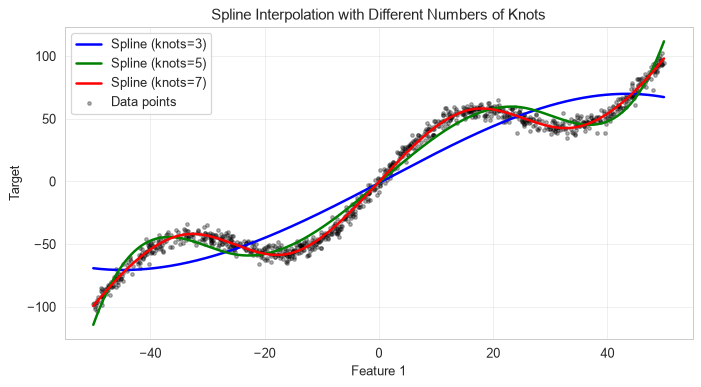

,Number of Knots,Jumlah fitur basis,MSE,R-squared
0,3,5,274.267019,0.904652
1,5,7,55.347798,0.980759
2,7,9,15.502097,0.994611


In [10]:
# Spline dengan jumlah knot berbeda
n_knots = [3, 5, 7]
plt.figure(figsize=(9, 4.5))

mse_scores = []
r2_scores = []

for n_knot, color in zip(n_knots, colors[:len(n_knots)]):
    # Pipeline: SplineTransformer (B-spline kubik) -> LinearRegression
    spline = SplineTransformer(n_knots=n_knot, degree=3)
    model = make_pipeline(spline, LinearRegression())
    model.fit(X, y)

    y_pred = model.predict(X_plot)      # kurva halus
    y_pred_train = model.predict(X)     # prediksi pada seluruh data

    # Metrik dihitung pada data yang sama dengan data fitting (in-sample), sesuai notebook asli
    mse_scores.append(mean_squared_error(y, y_pred_train))
    r2_scores.append(r2_score(y, y_pred_train))

    plt.plot(X_plot['feature1'], y_pred, label=f'Spline (knots={n_knot})',
             color=color, linewidth=2)

plt.scatter(X, y, color='black', alpha=0.3, s=8, label='Data points')
plt.xlabel('Feature 1')
plt.ylabel('Target')
plt.title('Spline Interpolation with Different Numbers of Knots')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

metrics_df = pd.DataFrame({
    'Number of Knots': n_knots,
    'Jumlah fitur basis': [k + 3 - 1 for k in n_knots],
    'MSE': mse_scores,
    'R-squared': r2_scores,
})
display(metrics_df)

**Interpretasi:**

- Dengan 3 knot (5 fungsi basis), spline hanya setara polinomial derajat 3–4 ($R^2$ 0.905). Dengan 5 knot (7 basis) $R^2$ melonjak ke **0.981**, dan dengan 7 knot (9 basis) mencapai **0.995** dengan MSE ≈ **15.5**.
- MSE 15.5 sudah sangat dekat dengan variansi *noise* sebenarnya ($4^2 = 16$), artinya spline 7 knot telah menangkap hampir seluruh struktur yang bisa dijelaskan; sisanya adalah *irreducible error*. Kurva pada plot mengikuti dua gelombang sinus dengan mulus tanpa osilasi liar di tepi seperti polinomial global.
- Catatan kritis: metrik di sini dihitung **in-sample** (pada data yang sama dengan data *fitting*), mengikuti notebook asli. Untuk memilih jumlah knot secara jujur, gunakan data uji atau validasi silang, karena menambah knot tanpa batas pada akhirnya akan *overfitting*.

## Latihan

Bagian ini mereproduksi tiga latihan di akhir chapter beserta solusinya (dari notebook *Exercise Solution*). Setiap latihan membuat dataset sintetis baru, memasang satu model teregularisasi, lalu membandingkan metrik pada data latih dan data uji.

**Teori singkat:** membandingkan metrik **latih vs uji** adalah cara paling sederhana mendiagnosis bias–variance. Galat latih jauh lebih kecil dari galat uji → *overfitting* (varians tinggi). Galat latih dan uji sama-sama besar → *underfitting* (bias tinggi, model terlalu sederhana atau penalti terlalu kuat). Untuk model dengan satu fitur, regularisasi tidak banyak berpengaruh pada varians — efek utamanya adalah sedikit menyusutkan kemiringan garis ke arah nol.

### Exercise 1: Implementing Ridge Regression

Training Metrics:
MSE: 1.9780
R²: 0.6575

Test Metrics:
MSE: 2.5628
R²: -0.0360

Koefisien: slope = 1.0992, intercept = 1.5719


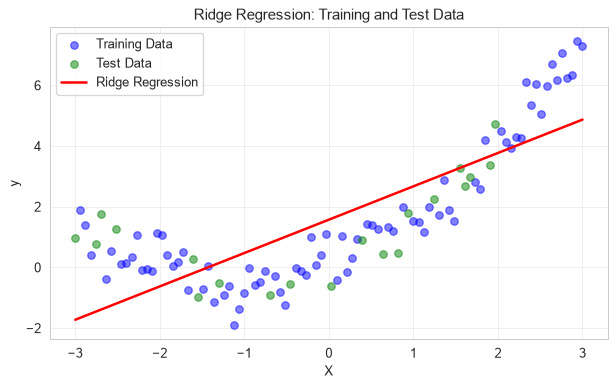

In [11]:
# Dataset sintetis kuadratik dengan noise
np.random.seed(123)
X = np.linspace(-3, 3, 100).reshape(-1, 1)
y = 0.5 * X.ravel()**2 + X.ravel() + np.random.normal(0, 0.5, 100)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=123)

# Ridge dengan alpha = 1.0 (kekuatan regularisasi)
ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train)

y_pred_train = ridge.predict(X_train)
y_pred_test = ridge.predict(X_test)

mse_train = mean_squared_error(y_train, y_pred_train)
r2_train = r2_score(y_train, y_pred_train)
mse_test = mean_squared_error(y_test, y_pred_test)
r2_test = r2_score(y_test, y_pred_test)

print('Training Metrics:')
print(f'MSE: {mse_train:.4f}')
print(f'R²: {r2_train:.4f}')
print('\nTest Metrics:')
print(f'MSE: {mse_test:.4f}')
print(f'R²: {r2_test:.4f}')
print(f'\nKoefisien: slope = {ridge.coef_[0]:.4f}, intercept = {ridge.intercept_:.4f}')

plt.figure(figsize=(8, 4.5))
plt.scatter(X_train, y_train, color='blue', alpha=0.5, label='Training Data')
plt.scatter(X_test, y_test, color='green', alpha=0.5, label='Test Data')

# Urutkan X agar garis halus
X_plot = np.sort(X, axis=0)
plt.plot(X_plot, ridge.predict(X_plot), color='red', linewidth=2, label='Ridge Regression')
plt.xlabel('X')
plt.ylabel('y')
plt.title('Ridge Regression: Training and Test Data')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Interpretasi:**

- Data dibangkitkan dari fungsi **kuadratik** $0.5x^2 + x$, tetapi Ridge hanya memasang **garis lurus**. Hasilnya $R^2$ latih 0.66 dan $R^2$ uji **−0.04** (lebih buruk daripada sekadar memprediksi rata-rata data uji). Ini kasus **underfitting / bias tinggi** akibat spesifikasi model yang salah, bukan masalah varians — regularisasi tidak dapat memperbaikinya.
- Slope yang diperoleh (≈1.10) mendekati koefisien linear sebenarnya (1), sedangkan intersep (≈1.57) "menyerap" rata-rata komponen kuadrat. Perbaikan yang wajar: `make_pipeline(PolynomialFeatures(2), Ridge(alpha=1.0))` agar model dapat menangkap lengkungan.

### Exercise 2: Implementing Lasso Regression

Training Metrics:


MSE: 0.2631
R²: 0.8814

Test Metrics:
MSE: 0.4239
R²: 0.8419

Slope Lasso = 2.4508 vs slope OLS = 2.8609 (nilai sebenarnya 3)


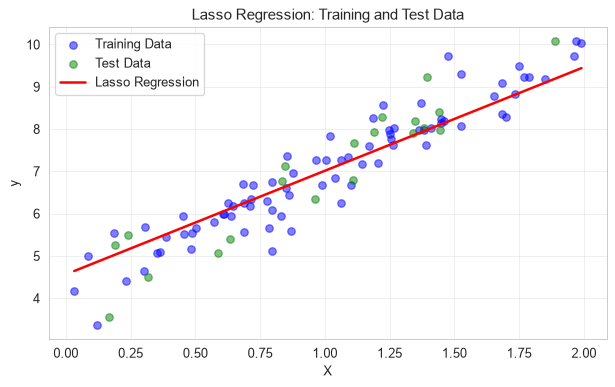

In [12]:
# Dataset linear: y = 4 + 3x + noise
np.random.seed(123)
X = 2 * np.random.rand(100, 1)
y = (4 + 3 * X + np.random.randn(100, 1) * 0.5).ravel()   # ravel -> target 1D

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=123)

# Lasso dengan alpha = 0.1
lasso = Lasso(alpha=0.1)
lasso.fit(X_train, y_train)

y_pred_train = lasso.predict(X_train)
y_pred_test = lasso.predict(X_test)

mse_train = mean_squared_error(y_train, y_pred_train)
r2_train = r2_score(y_train, y_pred_train)
mse_test = mean_squared_error(y_test, y_pred_test)
r2_test = r2_score(y_test, y_pred_test)

print('Training Metrics:')
print(f'MSE: {mse_train:.4f}')
print(f'R²: {r2_train:.4f}')
print('\nTest Metrics:')
print(f'MSE: {mse_test:.4f}')
print(f'R²: {r2_test:.4f}')
ols_slope = LinearRegression().fit(X_train, y_train).coef_[0]
print(f'\nSlope Lasso = {lasso.coef_[0]:.4f} vs slope OLS = {ols_slope:.4f} (nilai sebenarnya 3)')

plt.figure(figsize=(8, 4.5))
plt.scatter(X_train, y_train, color='blue', alpha=0.5, label='Training Data')
plt.scatter(X_test, y_test, color='green', alpha=0.5, label='Test Data')

X_plot = np.sort(X, axis=0)
plt.plot(X_plot, lasso.predict(X_plot), color='red', linewidth=2, label='Lasso Regression')
plt.xlabel('X')
plt.ylabel('y')
plt.title('Lasso Regression: Training and Test Data')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Interpretasi:**

- Model sesuai dengan bentuk data (linear), sehingga $R^2$ latih 0.88 dan uji **0.84**; MSE uji (0.42) sedikit di atas MSE latih (0.26) dan masih dekat variansi *noise* ($0.5^2=0.25$) — tidak ada overfitting berarti.
- Efek penyusutan L1 terlihat jelas: slope Lasso **2.45** sedangkan slope OLS **2.86** (nilai sebenarnya 3). Dengan satu fitur, soft-thresholding mengurangi koefisien sebesar kira-kira $\alpha/\operatorname{Var}(x)$; karena $x\sim U(0,2)$ memiliki varians kecil (~0.33), penyusutannya cukup besar (≈0.3–0.4). Di sini regularisasi justru menambah bias tanpa manfaat varians, karena tidak ada fitur yang perlu dibuang.

### Exercise 3: Implementing ElasticNet Regression

Training Metrics:
MSE: 4.6771
R²: 0.9849

Test Metrics:
MSE: 4.0393
R²: 0.9867

Slope ElasticNet = 3.0099 (nilai sebenarnya 3)


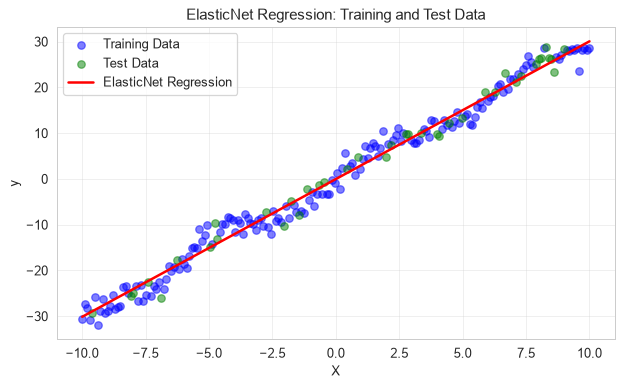

In [13]:
# Dataset: tren linear kuat + komponen sinus + noise
np.random.seed(123)
X = np.linspace(-10, 10, 200).reshape(-1, 1)
y = (3 * X + np.sin(X) * 2 + np.random.normal(0, 1.5, X.shape)).ravel()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=123)

# ElasticNet: alpha = kekuatan regularisasi, l1_ratio = proporsi L1 vs L2
elastic_net = ElasticNet(alpha=0.1, l1_ratio=0.5)
elastic_net.fit(X_train, y_train)

y_pred_train = elastic_net.predict(X_train)
y_pred_test = elastic_net.predict(X_test)

mse_train = mean_squared_error(y_train, y_pred_train)
r2_train = r2_score(y_train, y_pred_train)
mse_test = mean_squared_error(y_test, y_pred_test)
r2_test = r2_score(y_test, y_pred_test)

print('Training Metrics:')
print(f'MSE: {mse_train:.4f}')
print(f'R²: {r2_train:.4f}')
print('\nTest Metrics:')
print(f'MSE: {mse_test:.4f}')
print(f'R²: {r2_test:.4f}')
print(f'\nSlope ElasticNet = {elastic_net.coef_[0]:.4f} (nilai sebenarnya 3)')

plt.figure(figsize=(8, 4.5))
plt.scatter(X_train, y_train, color='blue', alpha=0.5, label='Training Data')
plt.scatter(X_test, y_test, color='green', alpha=0.5, label='Test Data')

X_plot = np.sort(X, axis=0)
plt.plot(X_plot, elastic_net.predict(X_plot), color='red', linewidth=2, label='ElasticNet Regression')
plt.xlabel('X')
plt.ylabel('y')
plt.title('ElasticNet Regression: Training and Test Data')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Interpretasi:**

- ElasticNet memperoleh $R^2$ ≈ **0.985** (latih) dan **0.987** (uji), dengan slope **3.01** — hampir persis nilai sebenarnya 3. Karena variansi $x$ di $[-10,10]$ besar (~33), penalti $\alpha=0.1$ relatif sangat kecil sehingga penyusutannya tidak terasa.
- MSE (~4–4.7) lebih besar dari variansi *noise* ($1.5^2=2.25$) karena komponen $2\sin(x)$ (variansi ≈ 2) tidak dapat dimodelkan oleh garis lurus. Metrik uji sedikit lebih baik daripada metrik latih — ini hanya variasi acak karena data uji kecil (40 titik), dan sekaligus menunjukkan bahwa model tidak overfitting.

## Ringkasan Chapter 5

1. **Model linear dan OLS.** Regresi linear memodelkan $\mathbf y = X\boldsymbol\beta + \boldsymbol\varepsilon$ dan OLS menyelesaikannya lewat normal equation $\hat{\boldsymbol\beta}=(X^\top X)^{-1}X^\top\mathbf y$. OLS tidak bias, tetapi variansnya $\sigma^2(X^\top X)^{-1}$ membengkak saat fitur berkorelasi tinggi atau jumlah fitur besar. Pada dataset 100 fitur dengan 50 pasangan kembar, OLS overfitting ($R^2$ latih 0.34 vs uji 0.06) dan menghasilkan koefisien kembar bertanda berlawanan yang tidak dapat ditafsirkan.
2. **Regularisasi = menukar sedikit bias dengan banyak varians.** Ridge (L2) menambah $\alpha\lVert\boldsymbol\beta\rVert_2^2$, memiliki solusi tertutup $(X^\top X+\alpha I)^{-1}X^\top\mathbf y$ yang selalu stabil, dan menyusutkan koefisien tanpa membuatnya nol. Lasso (L1) menambah $\alpha\lVert\boldsymbol\beta\rVert_1$, diselesaikan dengan coordinate descent + soft-thresholding, dan menghasilkan koefisien tepat nol (seleksi fitur) karena geometri daerah kendala L1 yang bersudut.
3. **ElasticNet** menggabungkan keduanya ($\alpha\rho\lVert\boldsymbol\beta\rVert_1 + \tfrac{\alpha(1-\rho)}{2}\lVert\boldsymbol\beta\rVert_2^2$): tetap sparse, tetapi lebih stabil untuk kelompok fitur berkorelasi (*grouping effect*). *Coefficient path plot* memperlihatkan bagaimana koefisien menyusut saat $\alpha$ naik. Pada data chapter ini ElasticNet($\alpha=1$, $\rho=0.5$) menjadi yang terbaik di antara model ber-$\alpha$ tetap ($R^2$ 0.15).
4. **$\alpha$ harus dipilih dengan validasi silang, dan skalanya bergantung pada data.** $\alpha=10$ pada Lasso praktis tidak berpengaruh karena koefisien berorde $10^4$–$10^5$; `LassoCV` memilih $\alpha\approx 9.4\times10^3$ dan menghasilkan model 12 fitur dengan $R^2$ uji tertinggi (0.205). Ingat juga bahwa `Lasso`/`ElasticNet` memakai faktor $\tfrac{1}{2n}$ sedangkan `Ridge` tidak, dan fitur sebaiknya distandardisasi sebelum diregularisasi.
5. **Model linear dapat menangkap non-linearitas lewat basis expansion.** `PolynomialFeatures` menambah suku $x^k$ (model tetap linear terhadap parameter). Derajat mengatur kompleksitas (bias–variance), dan fitur mentah berskala besar membuat matriks desain *ill-conditioned* — derajat 5 tanpa scaling gagal ($R^2$ 0.72), tetapi dengan `StandardScaler` mencapai 0.983. Plot residual membantu mendeteksi pola yang belum tertangkap.
6. **Spline** (`SplineTransformer`) memakai polinomial kubik sepotong-sepotong dengan basis B-spline yang lokal dan terkondisi baik. Jumlah knot mengatur fleksibilitas; dengan 7 knot MSE turun ke ~15.5, hampir sama dengan variansi *noise* (16).
7. **Latihan** menegaskan diagnosis latih-vs-uji: Ridge linear pada data kuadratik → underfitting (bias; perlu fitur polinomial); Lasso pada data linear → penyusutan slope (2.45 vs 2.86) tanpa manfaat; ElasticNet pada data dengan tren kuat → slope ≈ 3 dan $R^2$ ≈ 0.99.

**Pesan utama:** mulailah dengan model linear sebagai *baseline*, standardisasi fitur, gunakan regularisasi (Ridge untuk multikolinearitas, Lasso untuk sparsity/seleksi fitur, ElasticNet untuk keduanya) dengan $\alpha$ yang dipilih lewat validasi silang, dan perluas dengan polynomial/spline features ketika hubungan antara fitur dan target tidak linear.